In [1]:
from example_dg import get_dg_data

In [2]:
# physical parameters
amplitude = 0.25
frequency = 5.0     

# spatial discretization
nx = 64
ny = 32
Lx = 2.0
Ly = 1.0

# temporal discretization
dt = 0.05
T = 100.0

# Dataset creation
train_d, val_d, test_d = get_dg_data(randomized=False,
                                     amplitude=amplitude, frequency=frequency, 
                                     Lx=Lx, Ly=Ly, nx=nx, ny=ny,
                                     T=T, dt=dt)

In [3]:
train_d['x'].shape

(1600, 64, 32, 2)

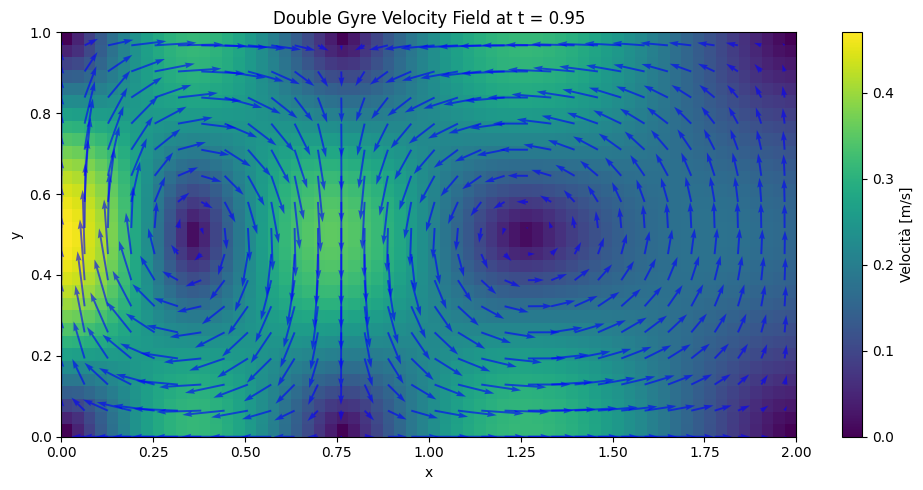

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Supponendo che train_d sia il tuo dizionario e x_grid, y_grid siano meshgrid
# Se x_grid e y_grid sono 1D, creiamo la meshgrid:
# X, Y = np.meshgrid(train_d['x_grid'], train_d['y_grid'])

# Estraiamo il primo snapshot (t=0)
# La struttura è (nx, ny, components) -> (64, 32, 2)
index = 19
snapshot = train_d['x'][index] 

u = snapshot[:, :, 0]
v = snapshot[:, :, 1]
magnitude = np.sqrt(u**2 + v**2)

plt.figure(figsize=(10, 5))

# 1. Plot del modulo della velocità (Heatmap)
# Usiamo l'estensione del dominio [0, 2]x[0, 1]
im = plt.imshow(magnitude.T, extent=[0, 2, 0, 1], origin='lower', 
                cmap='viridis', aspect='auto')
plt.colorbar(im, label='Velocità [m/s]')

# 2. Plot delle frecce (Vettori direzione)
# Sottocampioniamo per non affollare il grafico (es. ogni 2 o 4 punti)
skip = 2
x_coords = np.linspace(0, 2, 64)
y_coords = np.linspace(0, 1, 32)
X, Y = np.meshgrid(x_coords, y_coords)

plt.quiver(X[::skip, ::skip], Y[::skip, ::skip], 
           u.T[::skip, ::skip], v.T[::skip, ::skip], 
           color='blue', alpha=0.6, scale=5)

plt.title(f"Double Gyre Velocity Field at t = {train_d['t'][index]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

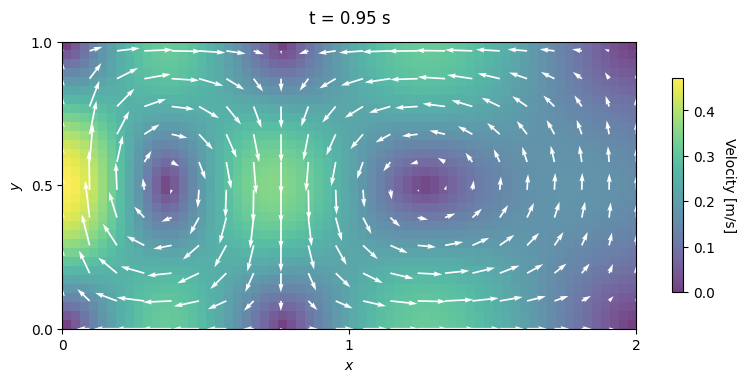

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_double_gyre(train_d, index):
    # 1. Estrazione dati
    snapshot = train_d['x'][index]
    time_val = train_d['t'][index]
    
    u = snapshot[:, :, 0]
    v = snapshot[:, :, 1]
    magnitude = np.sqrt(u**2 + v**2)
    
    # 2. Preparazione griglia
    nx, ny = u.shape
    x_coords = np.linspace(0, 2, nx)
    y_coords = np.linspace(0, 1, ny)
    X, Y = np.meshgrid(x_coords, y_coords)
    
    # Creazione figura
    plt.figure(figsize=(8, 4)) 
    
    # 3. Plot della Heatmap
    im = plt.imshow(magnitude.T, extent=[0, 2, 0, 1], origin='lower', 
                    cmap='viridis', aspect='auto', alpha=0.75)
    
    # Forza il rapporto 1:1 tra gli assi
    plt.gca().set_aspect('equal', adjustable='box')
    
    cbar = plt.colorbar(im, shrink=0.6) # shrink riduce la barra per adattarsi al plot 1:1
    cbar.set_label('Velocity [m/s]', rotation=270, labelpad=15)
    
    # 4. Plot delle frecce
    skip = 3
    plt.quiver(X[::skip, ::skip], Y[::skip, ::skip], 
               u.T[::skip, ::skip], v.T[::skip, ::skip], 
               color='white', alpha=1, scale=6, width=0.003)
    
    # 5. Posizionamento del Tempo "In alto"
    plt.text(0.5, 1.05, f"t = {time_val:.2f} s", 
             transform=plt.gca().transAxes, 
             fontsize=12, 
             ha='center', va='bottom')

    # Estetica assi e riduzione Ticks
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.xticks([0, 1, 2])
    plt.yticks([0, 0.5, 1])
    
    plt.tight_layout()
    plt.show()

# Esecuzione
plot_double_gyre(train_d, 19)

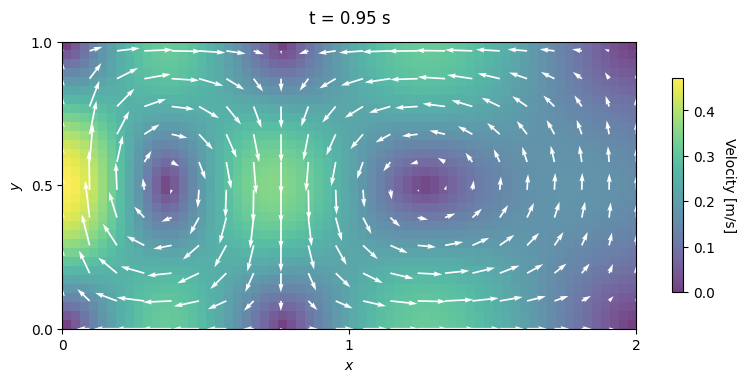

In [51]:
import numpy as np
import matplotlib.pyplot as plt

def plot_double_gyre(train_d, index, save_name=None):
    # 1. Estrazione dati
    snapshot = train_d['x'][index]
    time_val = train_d['t'][index]
    
    u = snapshot[:, :, 0]
    v = snapshot[:, :, 1]
    magnitude = np.sqrt(u**2 + v**2)
    
    # 2. Preparazione griglia
    nx, ny = u.shape
    x_coords = np.linspace(0, 2, nx)
    y_coords = np.linspace(0, 1, ny)
    X, Y = np.meshgrid(x_coords, y_coords)
    
    # Creazione figura
    plt.figure(figsize=(8, 4)) 
    
    # 3. Plot della Heatmap
    im = plt.imshow(magnitude.T, extent=[0, 2, 0, 1], origin='lower', 
                    cmap='viridis', aspect='auto', alpha=0.75)
    
    # Forza il rapporto 1:1 tra gli assi
    plt.gca().set_aspect('equal', adjustable='box')
    
    cbar = plt.colorbar(im, shrink=0.6)
    cbar.set_label('Velocity [m/s]', rotation=270, labelpad=15)
    
    # 4. Plot delle frecce
    skip = 3
    plt.quiver(X[::skip, ::skip], Y[::skip, ::skip], 
               u.T[::skip, ::skip], v.T[::skip, ::skip], 
               color='white', alpha=1, scale=6, width=0.003)
    
    # 5. Posizionamento del Tempo "In alto"
    plt.text(0.5, 1.05, f"t = {time_val:.2f} s", 
             transform=plt.gca().transAxes, 
             fontsize=12, 
             ha='center', va='bottom')

    # Estetica assi e riduzione Ticks
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.xticks([0, 1, 2])
    plt.yticks([0, 0.5, 1])
    
    plt.tight_layout()
    
    # SALVATAGGIO IN ALTA DEFINIZIONE
    if save_name:
        # Salvataggio in PNG (300 DPI per presentazioni/Word)
        plt.savefig(f"{save_name}.png", dpi=300, bbox_inches='tight')
        # Salvataggio in PDF (Vettoriale per tesi in LaTeX/stampa)
        # plt.savefig(f"{save_name}.pdf", bbox_inches='tight')
        # print(f"Grafico salvato come {save_name}.png e {save_name}.pdf")
    
    plt.show()

# Esecuzione e salvataggio
# Il file verrà salvato come 'double_gyre_snapshot_t0.55.png/pdf'
# 0 6 11 19
plot_double_gyre(train_d, 19, save_name="double_gyre3")

Griglia salvata come double_gyre_grid_compact.png


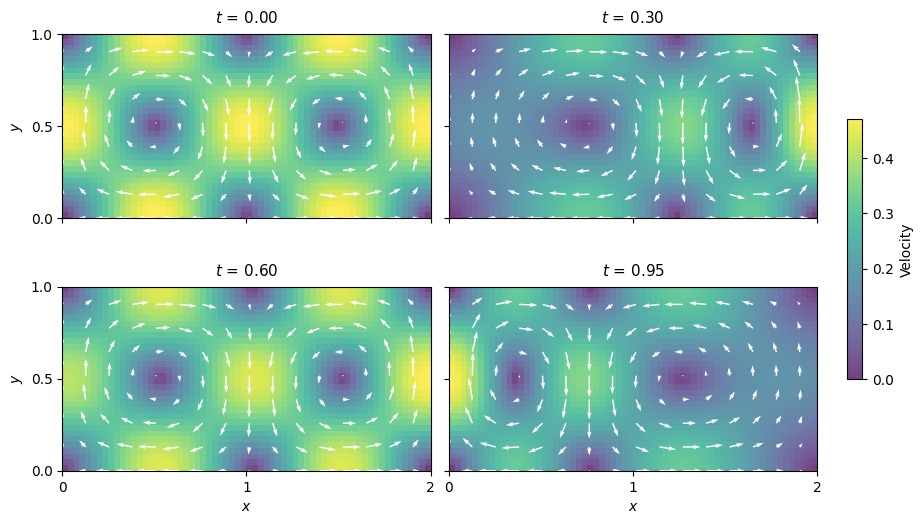

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_double_gyre_grid(train_d, indices, save_name=None):
    # sharex e sharey mantengono pulita la visualizzazione
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
    axes = axes.flatten() 
    
    im = None 
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        snapshot = train_d['x'][idx]
        time_val = train_d['t'][idx]
        
        u = snapshot[:, :, 0]
        v = snapshot[:, :, 1]
        magnitude = np.sqrt(u**2 + v**2)
        
        nx, ny = u.shape
        x_coords = np.linspace(0, 2, nx)
        y_coords = np.linspace(0, 1, ny)
        X, Y = np.meshgrid(x_coords, y_coords)
        
        # 1. Plot della Heatmap
        im = ax.imshow(magnitude.T, extent=[0, 2, 0, 1], origin='lower', 
                        cmap='viridis', aspect='auto', alpha=0.75)
        
        # 2. Rapporto d'aspetto 1:1 rigoroso
        ax.set_aspect('equal', adjustable='box')
        
        # 3. Plot delle frecce
        skip = 4 
        ax.quiver(X[::skip, ::skip], Y[::skip, ::skip], 
                  u.T[::skip, ::skip], v.T[::skip, ::skip], 
                  color='white', alpha=1, scale=6, width=0.004)
        
        # 4. Titolo (Tempo) più vicino al grafico per ridurre il gap visivo
        ax.set_title(f"$t$ = {time_val:.2f}", fontsize=11, pad=8)

        # 5. Gestione Ticks
        ax.set_xticks([0, 1, 2])
        ax.set_yticks([0, 0.5, 1])
        
        if i >= 2: ax.set_xlabel("$x$")
        if i % 2 == 0: ax.set_ylabel("$y$")

    # REGOLAZIONI LAYOUT:
    # hspace ridotto per avvicinare le righe
    # wspace ridotto per avvicinare le colonne
    fig.subplots_adjust(right=0.88, hspace=0.02, wspace=0.05)
    
    # Colorbar più sottile e corta (altezza 0.4 invece di 0.5)
    # Posizione centrata verticalmente (0.3 è il punto di partenza dal basso)
    cbar_ax = fig.add_axes([0.91, 0.3, 0.015, 0.4]) 
    fig.colorbar(im, cax=cbar_ax, label='Velocity')
    
    # Salvataggio
    if save_name:
        plt.savefig(f"{save_name}.png", dpi=300, bbox_inches='tight')
        print(f"Griglia salvata come {save_name}.png")
    
    plt.show()

# Esecuzione
indices_thesis = [0, 6, 12, 19]
plot_double_gyre_grid(train_d, indices_thesis, save_name="double_gyre_grid_compact")

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from celluloid import Camera
from matplotlib.animation import PillowWriter
from IPython.display import HTML

def create_double_gyre_gif(train_d, max_index, step=1, name="double_gyre.gif"):
    
    fig, ax = plt.subplots(figsize=(8, 4))
    camera = Camera(fig)
    
    for index in range(0, max_index, step):
        
        # Estrazione dati
        snapshot = train_d['x'][index]
        time_val = train_d['t'][index]
        
        u = snapshot[:, :, 0]
        v = snapshot[:, :, 1]
        magnitude = np.sqrt(u**2 + v**2)
        
        # Griglia
        nx, ny = u.shape
        x_coords = np.linspace(0, 2, nx)
        y_coords = np.linspace(0, 1, ny)
        X, Y = np.meshgrid(x_coords, y_coords)
        
        # Heatmap
        im = ax.imshow(magnitude.T, extent=[0, 2, 0, 1],
                       origin='lower', cmap='viridis',
                       aspect='auto', alpha=0.75)
        
        # Quiver
        skip = 3
        ax.quiver(X[::skip, ::skip], Y[::skip, ::skip],
                  u.T[::skip, ::skip], v.T[::skip, ::skip],
                  color='white', scale=6, width=0.003)
        
        # Tempo
        ax.text(0.5, 1.05, f"t = {time_val:.2f} s",
                transform=ax.transAxes,
                fontsize=12,
                ha='center', va='bottom')
        
        # Assi (fallo UNA VOLTA sola ma non crea problemi qui)
        ax.set_xlabel("$x$")
        ax.set_ylabel("$y$")
        ax.set_xticks([0, 1, 2])
        ax.set_yticks([0, 0.5, 1])
        ax.set_aspect('equal', adjustable='box')
        
        camera.snap()
    
    plt.tight_layout()
    
    animation = camera.animate()
    
    # Salvataggio (PRIMA di chiudere)
    animation.save(name, writer=PillowWriter(fps=10))
    
    plt.close(fig)
    
    return HTML(f"<img src='{name}'>")

In [9]:
create_double_gyre_gif(train_d, max_index=200, step=1)